In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline


In [2]:
%pip install compose

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
from sklearn.compose import ColumnTransformer

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [5]:
df=pd.read_csv('Ecomerse sale.csv')
df.shape

(138116, 46)

In [6]:
df.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [7]:
pd.set_option("display.max_columns",None)
df.head(2)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,NaN,NaN,3.6,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

In [9]:
df=df.drop(columns=['order_id','customer_id'])
df.head(3)

,order_date,order_time,order_status,sales_channel,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,2023-11-06,16:37:47,Completed,Mobile App,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,2025-12-24,01:22:36,Completed,Website,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,NaN,NaN,3.6,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,2021-07-05,14:24:21,Completed,Mobile App,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.0,3.0,On Time,NaN,NaN,4.3,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6


In [10]:
df.columns

Index(['order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_name', 'customer_age', 'gender', 'customer_segment',
       'customer_type', 'customer_city', 'customer_state', 'customer_country',
       'region', 'customer_postal_code', 'payment_method', 'payment_status',
       'currency', 'shipping_method', 'warehouse', 'delivery_days',
       'estimated_delivery_days', 'delivery_status', 'return_status',
       'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity',
       'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer',
       'customer_order_count'],
      dtype='object')

In [11]:
print(df['gender'].unique())

['Male' 'Female' 'Non-Binary']


In [12]:
print(df['customer_segment'].unique())

['Consumer' 'Premium' 'VIP' 'Business']


In [13]:
numerical_featurelist=["customer_age","customer_postal_code","loyalty_points_earned","loyalty_points_redeemed","quantity","gross_sales","discount_amount","tax_amount","shipping_cost","net_sales","product_cost","profit","profit_margin_percentage","customer_lifetime_value","is_repeat_customer","customer_order_count"]

In [14]:
for col in df.columns:
    if col not in numerical_featurelist:
        print(col,df[col].unique())
        print("-"*50)

order_date ['2023-11-06' '2025-12-24' '2021-07-05' ... '2023-03-31' '2022-07-20'
 '2025-04-03']
--------------------------------------------------
order_time ['16:37:47' '01:22:36' '14:24:21' ... '15:47:37' '02:29:35' '13:00:50']
--------------------------------------------------
order_status ['Completed' 'Pending' 'Cancelled' 'Returned']
--------------------------------------------------
sales_channel ['Mobile App' 'Website' 'Social Media' 'Marketplace']
--------------------------------------------------
customer_name ['Jasmine Ryan' 'Scott Chase' 'Marc Wheeler' ... 'Laura Potts'
 'Luis Miller' 'Deborah Saunders']
--------------------------------------------------
gender ['Male' 'Female' 'Non-Binary']
--------------------------------------------------
customer_segment ['Consumer' 'Premium' 'VIP' 'Business']
--------------------------------------------------
customer_type ['Loyal' 'Returning' 'New']
--------------------------------------------------
customer_city ['Lake Williamberg' 'K

In [15]:
print(df.isnull().sum())

order_date                       0
order_time                       0
order_status                     0
sales_channel                    0
customer_name                    0
customer_age                     0
gender                           0
customer_segment                 0
customer_type                    0
customer_city                    0
customer_state                   0
customer_country                 0
region                           0
customer_postal_code             0
payment_method                   0
payment_status                   0
currency                         0
shipping_method                  0
warehouse                        0
delivery_days                24557
estimated_delivery_days      24557
delivery_status                  0
return_status               128654
return_reason               128654
customer_rating              24557
review_sentiment             24557
customer_review              24557
marketing_channel                0
campaign_name       

In [16]:
df=df.drop(columns=["coupon_code","customer_rating","review_sentiment","customer_review","campaign_name","customer_review","return_status","return_reason","delivery_days","estimated_delivery_days"])

In [17]:
df.head(2)

,order_date,order_time,order_status,sales_channel,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_status,marketing_channel,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,2023-11-06,16:37:47,Completed,Mobile App,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,On Time,Direct,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,2025-12-24,01:22:36,Completed,Website,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,On Time,Direct,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11


In [18]:
print(df.isnull().sum())

order_date                  0
order_time                  0
order_status                0
sales_channel               0
customer_name               0
customer_age                0
gender                      0
customer_segment            0
customer_type               0
customer_city               0
customer_state              0
customer_country            0
region                      0
customer_postal_code        0
payment_method              0
payment_status              0
currency                    0
shipping_method             0
warehouse                   0
delivery_status             0
marketing_channel           0
loyalty_points_earned       0
loyalty_points_redeemed     0
quantity                    0
gross_sales                 0
discount_amount             0
tax_amount                  0
shipping_cost               0
net_sales                   0
product_cost                0
profit                      0
profit_margin_percentage    0
customer_lifetime_value     0
is_repeat_

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 35 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_date                138116 non-null  object 
 1   order_time                138116 non-null  object 
 2   order_status              138116 non-null  object 
 3   sales_channel             138116 non-null  object 
 4   customer_name             138116 non-null  object 
 5   customer_age              138116 non-null  int64  
 6   gender                    138116 non-null  object 
 7   customer_segment          138116 non-null  object 
 8   customer_type             138116 non-null  object 
 9   customer_city             138116 non-null  object 
 10  customer_state            138116 non-null  object 
 11  customer_country          138116 non-null  object 
 12  region                    138116 non-null  object 
 13  customer_postal_code      138116 non-null  i

In [20]:
print(df["order_status"].value_counts())

order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64


In [21]:
df.shape

(138116, 35)

In [22]:
df.columns

Index(['order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_name', 'customer_age', 'gender', 'customer_segment',
       'customer_type', 'customer_city', 'customer_state', 'customer_country',
       'region', 'customer_postal_code', 'payment_method', 'payment_status',
       'currency', 'shipping_method', 'warehouse', 'delivery_status',
       'marketing_channel', 'loyalty_points_earned', 'loyalty_points_redeemed',
       'quantity', 'gross_sales', 'discount_amount', 'tax_amount',
       'shipping_cost', 'net_sales', 'product_cost', 'profit',
       'profit_margin_percentage', 'customer_lifetime_value',
       'is_repeat_customer', 'customer_order_count'],
      dtype='object')

In [23]:
df.head(2)

,order_date,order_time,order_status,sales_channel,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_status,marketing_channel,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,2023-11-06,16:37:47,Completed,Mobile App,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,On Time,Direct,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,2025-12-24,01:22:36,Completed,Website,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,On Time,Direct,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11


In [24]:
df.describe()

,customer_age,customer_postal_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count
count,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000
mean,45.862681,50210.889310,103.991051,51.934128,5.615244,1375.384176,237.621614,122.462933,22.278080,1282.503575,708.903449,551.322046,45.065997,8971.639047,6.990559
std,16.467676,28569.767779,115.175640,73.217692,3.371289,1291.009554,378.779459,140.939368,16.022739,1169.274669,730.044970,516.300936,13.120357,4430.506588,2.444166
min,18.000000,516.000000,0.000000,0.000000,1.000000,6.310000,0.000000,0.340000,0.000000,5.800000,1.970000,-1281.590000,-59.550000,22.550000,1.000000
25%,32.000000,25509.000000,17.000000,3.000000,3.000000,458.920000,26.327500,34.650000,9.820000,448.200000,207.667500,190.757500,38.880000,5713.570000,5.000000
50%,46.000000,50183.000000,70.000000,25.000000,5.000000,995.730000,103.285000,77.010000,19.190000,950.760000,478.955000,408.395000,46.990000,8392.525000,7.000000
75%,60.000000,74898.000000,151.000000,71.000000,8.000000,1871.200000,277.125000,156.200000,30.750000,1744.582500,953.762500,752.845000,53.770000,11651.030000,9.000000
max,74.000000,99950.000000,1621.000000,1063.000000,24.000000,16051.190000,6759.020000,2091.520000,149.520000,16218.000000,9963.410000,7083.680000,77.590000,30268.440000,20.000000


In [25]:
def plot_histogram(df,column_name):
    plt.figure(figsize=(5,3))
    sns.histplot(df[column_name],kde=True)
    plt.title(f"Distribution of {column_name}")
    col_mean=df[column_name].mean()
    col_median=df[column_name].median()
    plt.axvline(col_mean,color="red",linestyle="--",label="mean")
    plt.axvline(col_median,color="green",linestyle="-",label="median")
    plt.legend()
    plt.show()
    

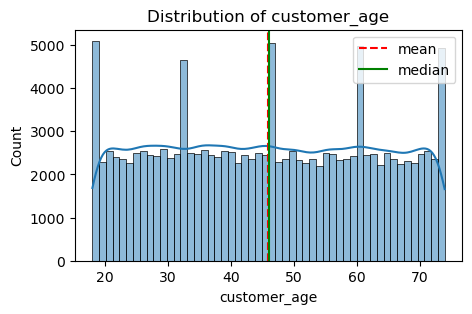

In [26]:
plot_histogram(df,"customer_age")

In [27]:
numerical_featurelist=["customer_age","customer_postal_code","loyalty_points_earned","loyalty_points_redeemed","quantity","gross_sales","discount_amount","tax_amount","shipping_cost","net_sales","product_cost","profit","profit_margin_percentage","customer_lifetime_value","is_repeat_customer","customer_order_count"]

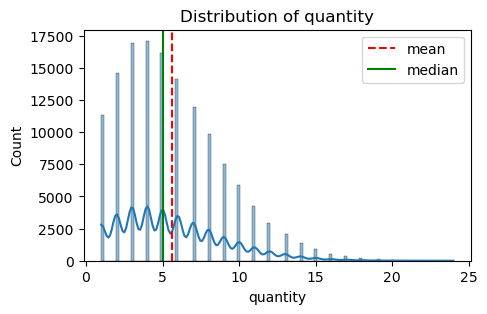

In [28]:
plot_histogram(df,"quantity")

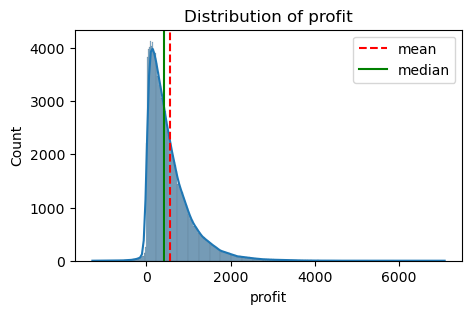

In [29]:
plot_histogram(df,"profit")

In [30]:
def plot_boxplot(df,column_name):
    plt.figure(figsize=(5,3))
    sns.boxplot(y=df[column_name])
    plt.title(f"box plot of{column_name}")
    plt.ylabel(column_name)
    plt.show()

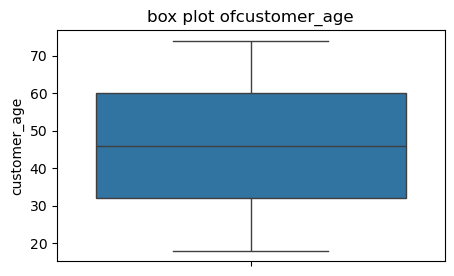

In [31]:
plot_boxplot(df,"customer_age")

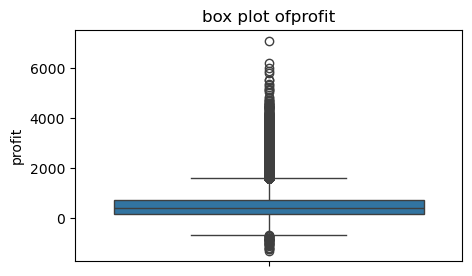

In [32]:
plot_boxplot(df,"profit")

In [33]:
df.describe()

,customer_age,customer_postal_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,customer_order_count
count,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000
mean,45.862681,50210.889310,103.991051,51.934128,5.615244,1375.384176,237.621614,122.462933,22.278080,1282.503575,708.903449,551.322046,45.065997,8971.639047,6.990559
std,16.467676,28569.767779,115.175640,73.217692,3.371289,1291.009554,378.779459,140.939368,16.022739,1169.274669,730.044970,516.300936,13.120357,4430.506588,2.444166
min,18.000000,516.000000,0.000000,0.000000,1.000000,6.310000,0.000000,0.340000,0.000000,5.800000,1.970000,-1281.590000,-59.550000,22.550000,1.000000
25%,32.000000,25509.000000,17.000000,3.000000,3.000000,458.920000,26.327500,34.650000,9.820000,448.200000,207.667500,190.757500,38.880000,5713.570000,5.000000
50%,46.000000,50183.000000,70.000000,25.000000,5.000000,995.730000,103.285000,77.010000,19.190000,950.760000,478.955000,408.395000,46.990000,8392.525000,7.000000
75%,60.000000,74898.000000,151.000000,71.000000,8.000000,1871.200000,277.125000,156.200000,30.750000,1744.582500,953.762500,752.845000,53.770000,11651.030000,9.000000
max,74.000000,99950.000000,1621.000000,1063.000000,24.000000,16051.190000,6759.020000,2091.520000,149.520000,16218.000000,9963.410000,7083.680000,77.590000,30268.440000,20.000000


In [34]:
data=df["profit"]
q3=np.quantile(data,0.75)
q1=np.quantile(data,0.25)
iqr=q3-q1
iqr

np.float64(562.0874999999999)

In [35]:
lwb=q1-(1.5*iqr)
lwb

np.float64(-652.3737499999997)

In [36]:
ub=q3+(1.5*iqr)
ub

np.float64(1595.9762499999997)

In [37]:
outlier=data[(data<=lwb)|(data>=ub)]
print("the following are the outlier in the boxplot:{}".format(outlier))

the following are the outlier in the boxplot:15        1683.42
23        1615.04
62        1598.59
88        3049.04
120       1642.77
           ...   
138009    1676.91
138023    1720.14
138051    1628.71
138056    1916.13
138092    1744.87
Name: profit, Length: 6514, dtype: float64


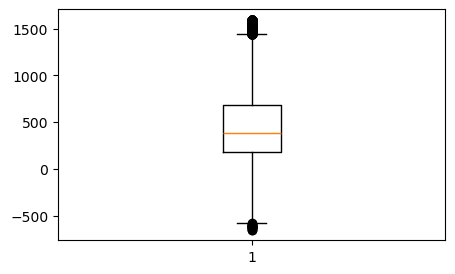

In [38]:
data2 = data[(data >= lwb) & (data <= ub)]
plt.figure(figsize=(5,3))
plt.boxplot(data2)
plt.show()

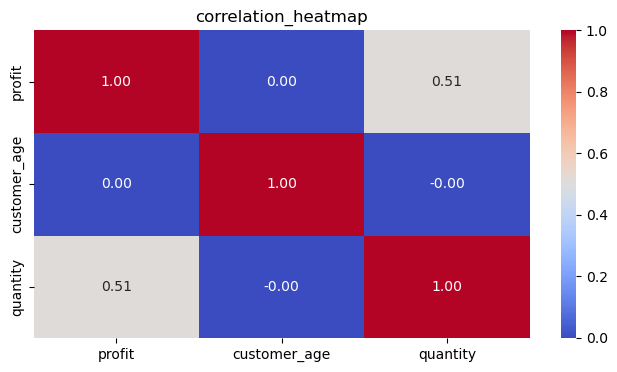

In [39]:
plt.figure(figsize=(8,4))
sns.heatmap(df[["profit","customer_age","quantity"]].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("correlation_heatmap")
plt.show()

In [40]:
df.columns

Index(['order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_name', 'customer_age', 'gender', 'customer_segment',
       'customer_type', 'customer_city', 'customer_state', 'customer_country',
       'region', 'customer_postal_code', 'payment_method', 'payment_status',
       'currency', 'shipping_method', 'warehouse', 'delivery_status',
       'marketing_channel', 'loyalty_points_earned', 'loyalty_points_redeemed',
       'quantity', 'gross_sales', 'discount_amount', 'tax_amount',
       'shipping_cost', 'net_sales', 'product_cost', 'profit',
       'profit_margin_percentage', 'customer_lifetime_value',
       'is_repeat_customer', 'customer_order_count'],
      dtype='object')

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 35 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_date                138116 non-null  object 
 1   order_time                138116 non-null  object 
 2   order_status              138116 non-null  object 
 3   sales_channel             138116 non-null  object 
 4   customer_name             138116 non-null  object 
 5   customer_age              138116 non-null  int64  
 6   gender                    138116 non-null  object 
 7   customer_segment          138116 non-null  object 
 8   customer_type             138116 non-null  object 
 9   customer_city             138116 non-null  object 
 10  customer_state            138116 non-null  object 
 11  customer_country          138116 non-null  object 
 12  region                    138116 non-null  object 
 13  customer_postal_code      138116 non-null  i

In [42]:
object_cols=df.select_dtypes(include="object").columns.to_list()
object_cols=["customer_age"]+object_cols
object_cols

['customer_age',
 'order_date',
 'order_time',
 'order_status',
 'sales_channel',
 'customer_name',
 'gender',
 'customer_segment',
 'customer_type',
 'customer_city',
 'customer_state',
 'customer_country',
 'region',
 'payment_method',
 'payment_status',
 'currency',
 'shipping_method',
 'warehouse',
 'delivery_status',
 'marketing_channel']

In [43]:
df['order_date'] = pd.to_datetime(df['order_date'])


In [44]:
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['order_day'] = df['order_date'].dt.day
df['order_dayofweek'] = df['order_date'].dt.dayofweek

In [45]:
df=df.drop(columns=['order_date'])
df.head(2)


,order_time,order_status,sales_channel,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_status,marketing_channel,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,order_year,order_month,order_day,order_dayofweek
0,16:37:47,Completed,Mobile App,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,On Time,Direct,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11,2023,11,6,0
1,01:22:36,Completed,Website,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,On Time,Direct,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11,2025,12,24,2


In [46]:
object_cols=df.select_dtypes(include="object").columns.to_list()
object_cols=["customer_age"]+object_cols
object_cols

['customer_age',
 'order_time',
 'order_status',
 'sales_channel',
 'customer_name',
 'gender',
 'customer_segment',
 'customer_type',
 'customer_city',
 'customer_state',
 'customer_country',
 'region',
 'payment_method',
 'payment_status',
 'currency',
 'shipping_method',
 'warehouse',
 'delivery_status',
 'marketing_channel']

In [47]:
x=df.drop(columns=['order_status'])
y=df['order_status']

In [48]:
df.head(5)

,order_time,order_status,sales_channel,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_status,marketing_channel,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,order_year,order_month,order_day,order_dayofweek
0,16:37:47,Completed,Mobile App,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,On Time,Direct,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11,2023,11,6,0
1,01:22:36,Completed,Website,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,On Time,Direct,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11,2025,12,24,2
2,14:24:21,Completed,Mobile App,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,On Time,YouTube,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6,2021,7,5,0
3,07:20:26,Completed,Social Media,Jennifer Smith,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,66329,Debit Card,Paid,USD,Express,WH-010,On Time,Email Marketing,54,10,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7,2023,1,21,5
4,09:46:21,Completed,Social Media,Jessica Wang,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,77306,Digital Wallet,Paid,INR,Standard,WH-013,Delayed,Direct,278,147,6,2474.52,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8,2022,5,13,4


In [49]:
print(df['order_status'].unique())

['Completed' 'Pending' 'Cancelled' 'Returned']


In [50]:
df['order_status'] = df['order_status'].replace({"Completed" : 0 , "Pending" : 1 , "Cancelled" : 2 , "Returned" : 3})

C:\Users\harsh\AppData\Local\Temp\ipykernel_21840\3041946112.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['order_status'] = df['order_status'].replace({"Completed" : 0 , "Pending" : 1 , "Cancelled" : 2 , "Returned" : 3})


In [51]:
df.head(2)

,order_time,order_status,sales_channel,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_status,marketing_channel,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,order_year,order_month,order_day,order_dayofweek
0,16:37:47,0,Mobile App,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,On Time,Direct,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11,2023,11,6,0
1,01:22:36,0,Website,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,On Time,Direct,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11,2025,12,24,2


In [52]:
from sklearn.preprocessing import LabelEncoder

In [53]:
object_columns=df.select_dtypes(include="object").columns

In [54]:
print(object_columns)

Index(['order_time', 'sales_channel', 'customer_name', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'payment_method', 'payment_status',
       'currency', 'shipping_method', 'warehouse', 'delivery_status',
       'marketing_channel'],
      dtype='object')


In [55]:
encoder={}

for column in object_columns:
    label_encoder=LabelEncoder()
    df[column]=label_encoder.fit_transform(df[column])
    encoder[column]=label_encoder

In [56]:
df.head()

,order_time,order_status,sales_channel,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_status,marketing_channel,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,order_year,order_month,order_day,order_dayofweek
0,47875,0,1,8713,55,1,1,0,6326,33,6,3,86040,5,1,6,3,2,3,1,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11,2023,11,6,0
1,3970,0,3,18331,26,1,2,0,5189,3,2,3,62538,4,2,3,0,4,3,1,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11,2025,12,24,2
2,41548,0,1,13544,69,0,2,0,12191,20,6,1,19993,2,1,6,1,14,3,9,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6,2021,7,5,0
3,21180,0,2,9285,65,1,1,0,15325,21,6,3,66329,4,1,6,1,9,3,2,54,10,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7,2023,1,21,5
4,28197,0,2,9672,34,0,1,0,8265,11,3,4,77306,5,1,5,3,12,1,1,278,147,6,2474.52,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8,2022,5,13,4


In [57]:
x=df.drop(columns=['order_status'])
y=df['order_status']

In [58]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(y_train.shape)

(110492,)


In [59]:
print(y_train.value_counts())

order_status
0    91009
3     7496
2     6658
1     5329
Name: count, dtype: int64


In [60]:
preprocessor = ColumnTransformer(transformers=[('cat', OneHotEncoder(
            handle_unknown='ignore'
        ), object_cols)
    ],
    remainder='passthrough'
)

In [61]:
models={
    "Decision Tree" : DecisionTreeClassifier(random_state=42),
    "Random Forest" : RandomForestClassifier(random_state=42)

}

In [62]:
cv_scores = {}
for model_name,model in models.items():
    print(f"Training{model_name} with default parameters")
    scores=cross_val_score(model,x_train,y_train,cv=15,scoring="accuracy")
    

TrainingDecision Tree with default parameters
TrainingRandom Forest with default parameters


In [66]:
rfc=RandomForestClassifier(random_state=42)
modelss=rfc.fit(x_train,y_train)
modelss

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [67]:
print(y_test.value_counts())

order_status
0    22550
3     1966
2     1740
1     1368
Name: count, dtype: int64


In [70]:
y_test_pred=modelss.predict(x_test)
y_test_pred

array([2, 0, 0, ..., 0, 0, 0], shape=(27624,))

In [71]:
print("Accuracy score:\n",accuracy_score(y_test,y_test_pred))

Accuracy score:
 1.0


In [72]:
print("confusion_matrix:\n",confusion_matrix(y_test,y_test_pred))

confusion_matrix:
 [[22550     0     0     0]
 [    0  1368     0     0]
 [    0     0  1740     0]
 [    0     0     0  1966]]


In [73]:
print("classification Report:\n",classification_report(y_test,y_test_pred))

classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     22550
           1       1.00      1.00      1.00      1368
           2       1.00      1.00      1.00      1740
           3       1.00      1.00      1.00      1966

    accuracy                           1.00     27624
   macro avg       1.00      1.00      1.00     27624
weighted avg       1.00      1.00      1.00     27624

